In [ ]:
from qiskit import *
from qiskit.visualization import plot_histogram
%matplotlib inline
from qiskit.providers.basic_provider import BasicProvider
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager



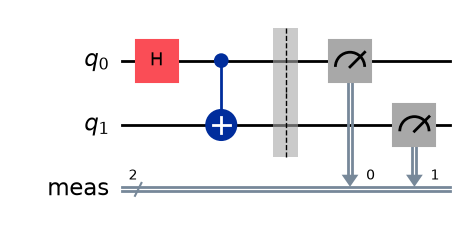

In [15]:
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.cx(0, 1)
circuit.measure_all()
circuit.draw(output='mpl');

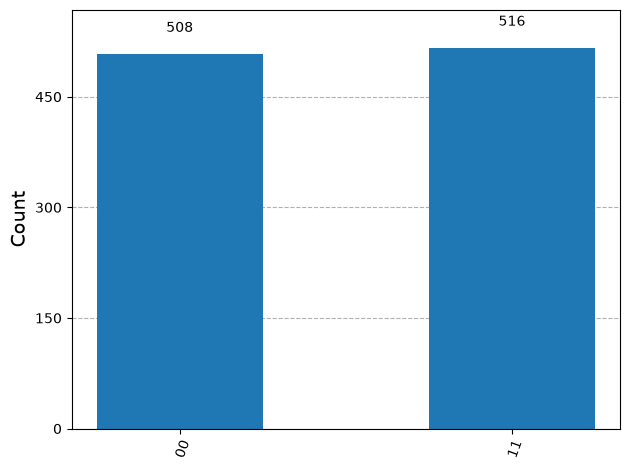

In [16]:
# UPDATE: Code updated after recording to resolve breaking changes from Qiskit 1.0
simulator = BasicProvider().get_backend('basic_simulator')
compiled_circuit = transpile(circuit, simulator)
result = simulator.run(compiled_circuit).result()
plot_histogram(result.get_counts());

In [ ]:
service = QiskitRuntimeService(
    channel='ibm_quantum_platform',
    token='my-token'
)

#service = QiskitRuntimeService()
#service = QiskitRuntimeService(channel='ibm_quantum', token='td1DCmPdR21EAelt_T7y-gi0eVZZK8S7mSygGRDPUULN')

qiskit_runtime_service._discover_account:WARNING:2026-11-22 14:48:14,074: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-22 14:48:16,989: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: quantum-computing-fundamentals quantum-computing-fundamentals. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


qiskit_runtime_service.backends:WARNING:2026-11-22 14:53:44,380: Loading instance: quantum-computing-fundamentals quantum-computing-fundamentals, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-22 14:53:45,630: Using instance: quantum-computing-fundamentals quantum-computing-fundamentals, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-22 14:53:46,719: Using instance: quantum-computing-fundamentals quantum-computing-fundamentals, plan: open


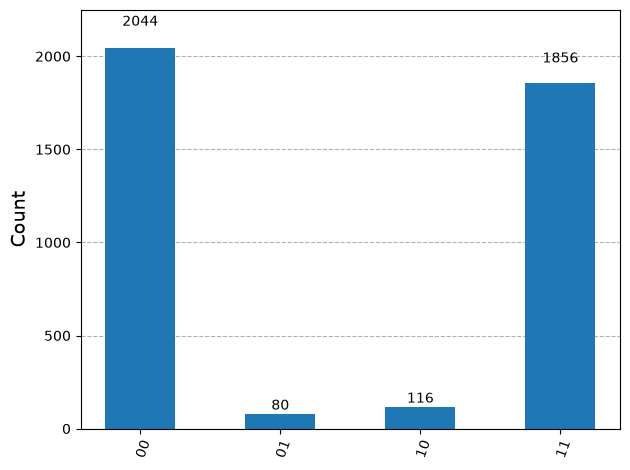

In [20]:
# UPDATE: Code updated after recording to resolve breaking changes from Qiskit 1.0
qcomp = service.least_busy(operational=True, simulator=False) # select least busy quantum computer
pm = generate_preset_pass_manager(backend=qcomp, optimization_level=1) # optimize the circuit for quantum execution
isa_circuit = pm.run(circuit) # modify circuit for qcomp's specific Instruction Set Architecture (ISA)

sampler = Sampler(qcomp)
job = sampler.run([isa_circuit])
result = job.result()
plot_histogram(result[0].data.meas.get_counts());
# NOTE: This may take a while... You can check job status on the IBM Quantum Platform web dashboard.